# Analisis Sentimen Game Brawl Stars Menggunakan Algoritma Random Forest
---
**Muhammad Taufiq Al Fauzi**

---

## 1. Import Library

In [ ]:
!pip install google-play-scraper pandas numpy scikit-learn nltk PySastrawi wordcloud matplotlib seaborn openpyxl joblib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.2/211.2 kB 9.5 MB/s eta 0:00:00


In [ ]:
# Manipulasi data
import pandas as pd
import numpy as np
import os
import re
import string
import time

# Scraping Google Play Store
from google_play_scraper import app, reviews, Sort

# Preprocessing teks
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# Download resource NLTK
import nltk
nltk.download('punkt_tab')
nltk.download('stopwords')

# Ekstraksi fitur & pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline

# Model
from sklearn.ensemble import RandomForestClassifier

# Evaluasi & seleksi model
from sklearn.model_selection import (
    train_test_split, StratifiedKFold,
    cross_val_score, cross_validate,
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix,
    make_scorer, roc_curve, roc_auc_score,
)

# Visualisasi
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# Simpan model
import joblib

print('✅ Semua library berhasil diimport')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


✅ Semua library berhasil diimport


---
## 2. Scraping Ulasan Google Play Store

In [ ]:
APP_ID      = 'com.supercell.brawlstars'
LANG        = 'id'
COUNTRY     = 'id'
JUMLAH_DATA = 5000
OUTPUT_DIR  = 'data'
OUTPUT_FILE = f'{OUTPUT_DIR}/ulasan_brawl_stars_raw.csv'

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs('output', exist_ok=True)

print(f'App ID   : {APP_ID}')
print(f'Target   : {JUMLAH_DATA} ulasan')
print(f'Bahasa   : {LANG} | Negara: {COUNTRY}')

# Ambil info aplikasi
info_app = app(APP_ID, lang=LANG, country=COUNTRY)

print('=' * 50)
print(f"Nama App    : {info_app['title']}")
print(f"Developer   : {info_app['developer']}")
print(f"Rating      : {info_app['score']} ⭐")
print(f"Total Rating: {info_app['ratings']:,}")
print(f"Installs    : {info_app['installs']}")
print('=' * 50)

App ID   : com.supercell.brawlstars
Target   : 5000 ulasan
Bahasa   : id | Negara: id
Nama App    : Brawl Stars
Developer   : Supercell
Rating      : 3.582405 ⭐
Total Rating: 25,914,083
Installs    : 500.000.000+


In [ ]:
semua_ulasan = []
token_lanjut = None
batch_size   = 200

print(f'Mulai scraping {JUMLAH_DATA} ulasan...')

while len(semua_ulasan) < JUMLAH_DATA:
    sisa  = JUMLAH_DATA - len(semua_ulasan)
    ambil = min(batch_size, sisa)

    hasil, token_lanjut = reviews(
        APP_ID, lang=LANG, country=COUNTRY,
        sort=Sort.NEWEST, count=ambil,
        continuation_token=token_lanjut
    )

    if not hasil:
        print('Tidak ada ulasan lagi tersedia.')
        break

    semua_ulasan.extend(hasil)
    print(f'  Terkumpul: {len(semua_ulasan)} ulasan...')

    if token_lanjut is None:
        print('Semua halaman telah diambil.')
        break

print(f'\n✅ Total ulasan berhasil diambil: {len(semua_ulasan)}')

Mulai scraping 5000 ulasan...
  Terkumpul: 200 ulasan...
  Terkumpul: 400 ulasan...
  Terkumpul: 600 ulasan...
  Terkumpul: 800 ulasan...
  Terkumpul: 1000 ulasan...
  Terkumpul: 1200 ulasan...
  Terkumpul: 1400 ulasan...
  Terkumpul: 1600 ulasan...
  Terkumpul: 1800 ulasan...
  Terkumpul: 2000 ulasan...
  Terkumpul: 2200 ulasan...
  Terkumpul: 2400 ulasan...
  Terkumpul: 2600 ulasan...
  Terkumpul: 2800 ulasan...
  Terkumpul: 3000 ulasan...
  Terkumpul: 3200 ulasan...
  Terkumpul: 3400 ulasan...
  Terkumpul: 3600 ulasan...
  Terkumpul: 3800 ulasan...
  Terkumpul: 4000 ulasan...
  Terkumpul: 4200 ulasan...
  Terkumpul: 4400 ulasan...
  Terkumpul: 4600 ulasan...
  Terkumpul: 4800 ulasan...
  Terkumpul: 5000 ulasan...

✅ Total ulasan berhasil diambil: 5000


In [ ]:
df_raw = pd.DataFrame(semua_ulasan)
df_raw = df_raw[['reviewId','userName','content','score','thumbsUpCount','at','appVersion']]
df_raw.rename(columns={
    'reviewId'     : 'id_ulasan',
    'userName'     : 'nama_pengguna',
    'content'      : 'ulasan',
    'score'        : 'rating',
    'thumbsUpCount': 'jumlah_like',
    'at'           : 'tanggal',
    'appVersion'   : 'versi_app',
}, inplace=True)

print(f'Shape data mentah: {df_raw.shape}')
df_raw.head(5)

Shape data mentah: (5000, 7)


,id_ulasan,nama_pengguna,ulasan,rating,jumlah_like,tanggal,versi_app
0,6e2fdf63-f9cd-4ce2-8c0f-1ffe17869474,Dev_XXBO,The game has the nicest design in a fighting g...,5,0,2026-06-28 06:46:31,67.306
1,a8d574e7-d9ef-46f5-96f9-cab18a4fba79,Ret Peri,gamenya keren banget aku ketagihan gamenya kal...,5,0,2026-06-28 04:05:10,67.306
2,e95dd01f-77b7-4127-b299-34736a3cfefd,Joe Silalahi,gak bisa masuk ke akun 2022,1,0,2026-06-28 02:07:08,None
3,276fc280-7bdf-4a56-ae30-c485119e891e,Abang Baim,memang terbaik,5,0,2026-06-28 00:59:14,67.306
4,37ca78c8-d645-4129-9efe-2b546d9a2972,Drk Ryy,the signal always bad during the match.why sup...,1,0,2026-06-27 23:54:27,None


✅ Data mentah disimpan ke: data/ulasan_magic_chest_gogo_raw.csv

Distribusi Rating Bintang:
rating
1    1805
2     305
3     347
4     360
5    2183
Name: count, dtype: int64


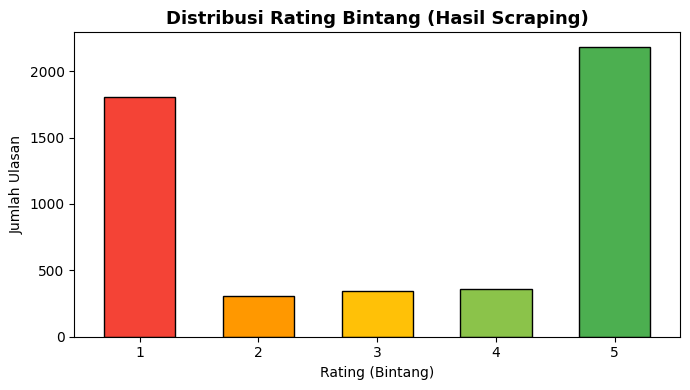

In [ ]:
df_raw.to_csv(OUTPUT_FILE, index=False, encoding='utf-8-sig')
print(f'✅ Data mentah disimpan ke: {OUTPUT_FILE}')

print('\nDistribusi Rating Bintang:')
print(df_raw['rating'].value_counts().sort_index())

plt.figure(figsize=(7, 4))
df_raw['rating'].value_counts().sort_index().plot(
    kind='bar',
    color=['#F44336','#FF9800','#FFC107','#8BC34A','#4CAF50'],
    edgecolor='black', width=0.6
)
plt.title('Distribusi Rating Bintang (Hasil Scraping)', fontsize=13, fontweight='bold')
plt.xlabel('Rating (Bintang)')
plt.ylabel('Jumlah Ulasan')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('output/distribusi_rating.png', dpi=150)
plt.show()

---
## 3. Load & Validasi Dataset Hasil Scraping

In [ ]:
df = pd.read_csv(OUTPUT_FILE, encoding='utf-8-sig')

print(f'Jumlah data  : {len(df)}')
print(f'Kolom        : {df.columns.tolist()}')
print(f'Rentang tanggal: {df["tanggal"].min()} s/d {df["tanggal"].max()}')
df.head(5)

Jumlah data  : 5000
Kolom        : ['id_ulasan', 'nama_pengguna', 'ulasan', 'rating', 'jumlah_like', 'tanggal', 'versi_app']
Rentang tanggal: 2024-12-06 07:51:23 s/d 2026-06-28 06:46:31


,id_ulasan,nama_pengguna,ulasan,rating,jumlah_like,tanggal,versi_app
0,6e2fdf63-f9cd-4ce2-8c0f-1ffe17869474,Dev_XXBO,The game has the nicest design in a fighting g...,5,0,2026-06-28 06:46:31,67.306
1,a8d574e7-d9ef-46f5-96f9-cab18a4fba79,Ret Peri,gamenya keren banget aku ketagihan gamenya kal...,5,0,2026-06-28 04:05:10,67.306
2,e95dd01f-77b7-4127-b299-34736a3cfefd,Joe Silalahi,gak bisa masuk ke akun 2022,1,0,2026-06-28 02:07:08,NaN
3,276fc280-7bdf-4a56-ae30-c485119e891e,Abang Baim,memang terbaik,5,0,2026-06-28 00:59:14,67.306
4,37ca78c8-d645-4129-9efe-2b546d9a2972,Drk Ryy,the signal always bad during the match.why sup...,1,0,2026-06-27 23:54:27,NaN


In [ ]:
print('Missing values:')
print(df.isnull().sum())
print(f'\nJumlah duplikat: {df.duplicated(subset=["id_ulasan"]).sum()}')

df.drop_duplicates(subset=['id_ulasan'], inplace=True)
df.dropna(subset=['ulasan'], inplace=True)
df = df[df['ulasan'].str.strip() != '']
df.reset_index(drop=True, inplace=True)

print(f'\nJumlah data bersih: {len(df)}')

Missing values:
id_ulasan           0
nama_pengguna       0
ulasan              0
rating              0
jumlah_like         0
tanggal             0
versi_app        1462
dtype: int64

Jumlah duplikat: 0

Jumlah data bersih: 5000


---
## 4. Pelabelan Otomatis — Rating-Based
> Label sentimen ditentukan berdasarkan **rating bintang** yang diberikan pengguna
> langsung di Google Play Store — label paling valid karena berasal dari pengguna itu sendiri.
>
> **Aturan pelabelan:**
> | Rating | Label | Alasan |
> |--------|-------|--------|
> | ⭐1 – ⭐2 | Negatif (0) | Pengguna tidak puas |
> | ⭐3 | Dihapus | Netral/ambigu, tidak representatif |
> | ⭐4 – ⭐5 | Positif (1) | Pengguna puas |
>
> Pendekatan ini umum digunakan pada penelitian analisis sentimen ulasan aplikasi
> (Medhat et al., 2014; Garg & Sharma, 2020).

In [ ]:
# ── Hapus rating 3 (netral/ambigu) ──────────────────────────
n_awal = len(df)
df = df[df['rating'] != 3].copy()
n_hapus_netral = n_awal - len(df)

# ── Beri label berdasarkan rating ────────────────────────────
df['label'] = df['rating'].apply(lambda r: 1 if r >= 4 else 0)
df.reset_index(drop=True, inplace=True)

print(f'Data awal          : {n_awal:,}')
print(f'Rating 3 dihapus   : {n_hapus_netral:,}')
print(f'Data setelah labeling: {len(df):,}')
print()

# ── Distribusi label ─────────────────────────────────────────
counts = df['label'].value_counts().sort_index(ascending=False)
total  = counts.sum()
print('Distribusi Label:')
for lbl, cnt in counts.items():
    nama = 'Positif' if lbl == 1 else 'Negatif'
    print(f'  {nama}: {cnt:,} ({cnt/total*100:.1f}%)')

Data awal          : 5,000
Rating 3 dihapus   : 347
Data setelah labeling: 4,653

Distribusi Label:
  Positif: 2,543 (54.7%)
  Negatif: 2,110 (45.3%)


/tmp/ipykernel_801/3508891676.py:43: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_801/3508891676.py:44: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  plt.savefig('output/distribusi_label_rating.png', dpi=150)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


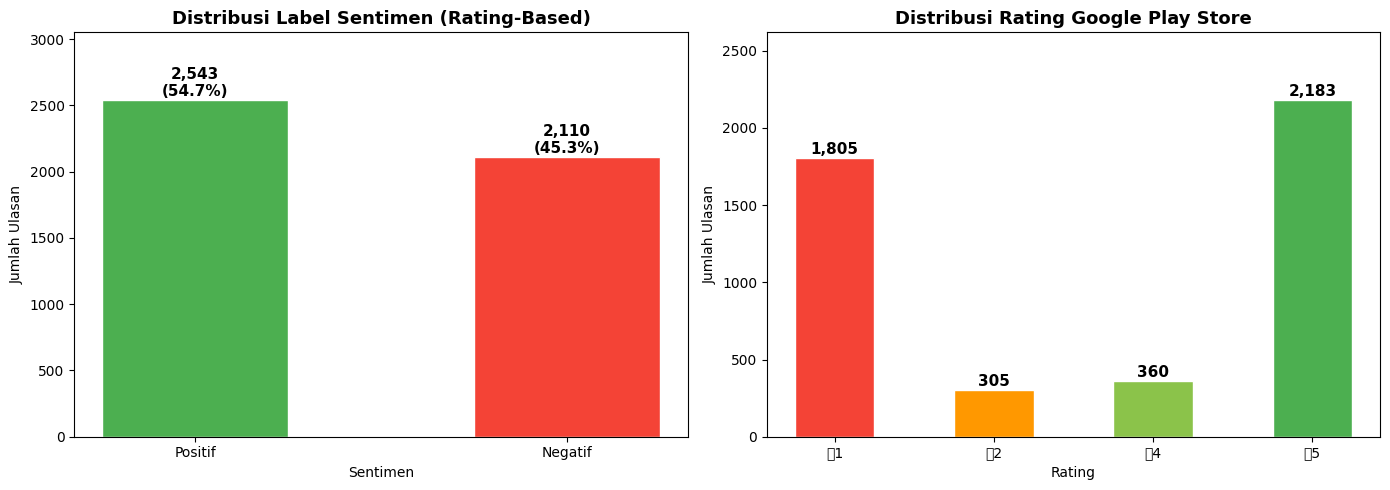

✅ Data berlabel disimpan ke: data/hasil_labeling_rating.xlsx


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Kiri: Distribusi label ────────────────────────────────────
label_names  = {1: 'Positif', 0: 'Negatif'}
counts       = df['label'].value_counts().sort_index(ascending=False)
total_labels = counts.sum()
colors       = ['#4CAF50', '#F44336']

bars = axes[0].bar(
    [label_names[i] for i in counts.index],
    counts.values,
    color=colors, edgecolor='white', width=0.5
)
axes[0].set_title('Distribusi Label Sentimen (Rating-Based)',
                  fontsize=13, fontweight='bold')
axes[0].set_xlabel('Sentimen')
axes[0].set_ylabel('Jumlah Ulasan')
axes[0].set_ylim(0, counts.max() * 1.2)
for bar, val in zip(bars, counts.values):
    pct = val / total_labels * 100
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 f'{val:,}\n({pct:.1f}%)',
                 ha='center', va='bottom', fontweight='bold', fontsize=11)

# ── Kanan: Distribusi rating asli ────────────────────────────
rating_counts = df['rating'].value_counts().sort_index()
rating_colors = ['#F44336', '#FF9800', '#8BC34A', '#4CAF50']

bars2 = axes[1].bar(
    [f'⭐{r}' for r in rating_counts.index],
    rating_counts.values,
    color=rating_colors, edgecolor='white', width=0.5
)
axes[1].set_title('Distribusi Rating Google Play Store',
                  fontsize=13, fontweight='bold')
axes[1].set_xlabel('Rating')
axes[1].set_ylabel('Jumlah Ulasan')
axes[1].set_ylim(0, rating_counts.max() * 1.2)
for bar, val in zip(bars2, rating_counts.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 f'{val:,}', ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.savefig('output/distribusi_label_rating.png', dpi=150)
plt.show()

# ── Simpan data berlabel ke Excel ────────────────────────────
df[['id_ulasan', 'ulasan', 'rating', 'label']].to_excel(
    'data/hasil_labeling_rating.xlsx', index=False)
print('✅ Data berlabel disimpan ke: data/hasil_labeling_rating.xlsx')

---
## 5. Preprocessing

In [ ]:
factory = StemmerFactory()
stemmer = factory.create_stemmer()

stop_words = set(stopwords.words('indonesian'))

# Kata yang WAJIB dipertahankan untuk analisis sentimen
kata_penting_sentimen = {
    'tidak', 'bukan', 'belum', 'jangan', 'tanpa', 'tak',  # negasi
    'sangat', 'sekali',                                     # intensifier
    'banyak', 'sering', 'selalu', 'jarang',
    'lama', 'lambat', 'cepat', 'susah', 'sulit',       # frekuensi
}
stop_words -= kata_penting_sentimen

custom_stopwords = {'game', 'nya', 'ya', 'yg', 'udah', 'aja', 'sih', 'deh'}
stop_words.update(custom_stopwords)

slang_dict = {
    # Negasi
    'gak': 'tidak', 'ga': 'tidak', 'gk': 'tidak', 'g': 'tidak',
    'ngak': 'tidak', 'ngk': 'tidak', 'ngga': 'tidak', 'kaga': 'tidak',
    # Kata Hubung & Penunjuk
    'yg': 'yang', 'tp': 'tapi', 'tpi': 'tapi', 'kalo': 'kalau', 'klo': 'kalau',
    'ama': 'sama', 'ni': 'ini', 'nih': 'ini', 'tuh': 'itu', 'ny': 'nya',
    # Keterangan & Kata Sifat
    'bgt' : 'banget', 'bngt': 'banget',
    'aja': 'saja', 'aj': 'saja', 'cuma': 'hanya',
    'udh': 'sudah', 'dah': 'sudah', 'udah': 'sudah',
    'trus': 'terus', 'mulu': 'terus', 'biar': 'agar',
    'kek': 'seperti', 'kaya': 'seperti', 'gini': 'begini', 'gitu': 'begitu',
    'abis': 'habis', 'plis': 'tolong', 'usah': 'perlu',
    # Kata Kerja
    'maen': 'main', 'dpt': 'dapat', 'dapet': 'dapat',
    'liat': 'lihat', 'kasi': 'kasih', 'pake': 'pakai', 'tau': 'tahu',
    # Istilah Spesifik Game & Typo
    'gem': 'game', 'geme': 'game', 'apk': 'aplikasi', 'bgus': 'bagus', 'geem': 'game',
    'ml': 'mobile legends', 'mlbb': 'mobile legends',
    'ngebug': 'bug', 'skil': 'skill', 'good' : 'bagus', 'god': 'bagus',   # 'good' → hapus_huruf_berulang → 'god'
    'win': 'menang', 'lose': 'kalah', 'op': 'overpower', 'gg': 'bagus', 'bot': 'komputer',
    # ── Kendala Teknis: Lag ──────────────────────────────────────
    'ngelag': 'lag', 'kelag': 'lag', 'lagg': 'lag', 'lags': 'lag',
    'laggy': 'lag', 'ngeleg': 'lag', 'lemot': 'lambat',
    'lelet': 'lambat', 'lambat': 'lambat', 'berat': 'berat',
    'fps': 'fps rendah', 'lowfps': 'fps rendah', 'patah': 'fps rendah',
    'patah patah': 'fps rendah', 'stuttering': 'fps rendah',
    'delay': 'lag', 'delai': 'lag', 'ping': 'ping tinggi',
    'highping': 'ping tinggi', 'conect': 'koneksi', 'koneksi': 'koneksi',
    'disconnect': 'putus koneksi', 'dc': 'putus koneksi',
    'dc': 'putus koneksi', 'ngedc': 'putus koneksi', 'kedc': 'putus koneksi',
    # ── Kendala Teknis: Bug & Error ──────────────────────────────
    'ngebug': 'bug', 'kebug': 'bug', 'bugg': 'bug', 'bugs': 'bug',
    'buggy': 'bug', 'glitch': 'bug', 'eror': 'error', 'errror': 'error',
    'error': 'error', 'galat': 'error', 'crash': 'crash',
    'ngecrash': 'crash', 'kecrash': 'crash', 'crass': 'crash',
    'force close': 'crash', 'fc': 'crash', 'nutup': 'crash',
    'nutup sendiri': 'crash', 'keluar sendiri': 'crash',
    'mati sendiri': 'crash', 'restart sendiri': 'crash',
    # ── Kendala Teknis: Server & Maintenance ────────────────────
    'server': 'server', 'srver': 'server', 'sever': 'server',
    'maintenance': 'pemeliharaan', 'matiin': 'pemeliharaan',
    'down': 'server mati', 'serverdown': 'server mati',
    'gangguan': 'gangguan', 'masalah': 'masalah',
    'update': 'pembaruan', 'updet': 'pembaruan', 'upd8': 'pembaruan',
    'patch': 'pembaruan', 'hotfix': 'pembaruan',
    # ── Kendala Akun & Transaksi ─────────────────────────────────
    'banned': 'akun diblokir', 'keban': 'akun diblokir', 'diband': 'akun diblokir',
    'ban': 'akun diblokir', 'suspend': 'akun diblokir',
    'hilang': 'hilang', 'kehilangan': 'hilang', 'reset': 'reset akun',
    'refund': 'pengembalian dana', 'tipu': 'penipuan', 'scam': 'penipuan',
    'curang': 'curang', 'cheat': 'curang', 'hacker': 'curang',
    'hack': 'curang', 'modif': 'curang',
    # Normalisasi Makian
    'asu': 'sialan', 'ajg': 'sialan', 'anjing': 'sialan', 'taik' : 'tai',
    'bgst': 'sialan', 'babi': 'sialan',
    'tolol': 'sialan', 'goblok': 'sialan', 'bego': 'sialan',
    'kontol': 'sialan', 'memek': 'sialan', 'bangsat': 'sialan', 'kampret': 'sialan',
}

def normalize_slang(text):
    """
    Normalisasi kata slang. Cek frasa multi-kata terlebih dahulu,
    kemudian kata tunggal.
    """
    # Cek frasa multi-kata (2 kata) dulu
    words = text.split()
    hasil = []
    i = 0
    while i < len(words):
        bigram = words[i] + ' ' + words[i + 1] if i + 1 < len(words) else None
        if bigram and bigram in slang_dict:
            hasil.append(slang_dict[bigram])
            i += 2
        else:
            hasil.append(slang_dict.get(words[i], words[i]))
            i += 1
    return ' '.join(hasil)

def hapus_huruf_berulang(text):
    """
    Normalisasi huruf berulang per kata.
    Contoh: 'seruu' → 'seru', 'bagusss' → 'bagus', 'tidakkkk' → 'tidak'
    Menggunakan loop bertahap agar konvergen:
      seruu → seru (bukan ser)
    """
    import re
    words = text.split()
    hasil = []
    for word in words:
        prev = None
        current = word
        # Ulangi hingga tidak ada perubahan (konvergen)
        while prev != current:
            prev = current
            current = re.sub(r'(.)\1+', r'\1', current)
        hasil.append(current)
    return ' '.join(hasil)

def preprocess(text):
    # 1. Lowercase
    text = text.lower()
    # 2. Hapus URL
    text = re.sub(r'http\S+|www\S+', '', text)
    # 3. Hapus emoji & karakter non-ASCII
    text = text.encode('ascii', 'ignore').decode('ascii')
    # 4. Hapus angka & tanda baca
    text = re.sub(r'[^a-z\s]', ' ', text)
    # 5. Normalisasi huruf berulang ('seruu' → 'seru', 'gakk' → 'gak')
    text = hapus_huruf_berulang(text)
    # 6. Normalisasi slang (agar 'good' → 'bagus')
    text = normalize_slang(text)
    # 7. Hapus spasi berlebih
    text = re.sub(r'\s+', ' ', text).strip()
    # 8. Tokenisasi
    tokens = word_tokenize(text)
    # 9. Hapus stopwords
    tokens = [t for t in tokens if t not in stop_words and len(t) > 1]
    # 10. Stemming
    tokens = [stemmer.stem(t) for t in tokens]
    return ' '.join(tokens)

print('✅ Fungsi preprocessing siap.')

✅ Fungsi preprocessing siap.


In [ ]:
df['ulasan_bersih'] = df['ulasan'].apply(preprocess)
df[['ulasan', 'ulasan_bersih']].head(5)

,ulasan,ulasan_bersih
0,The game has the nicest design in a fighting g...,the has the nicest design in fighting that is ...
1,gamenya keren banget aku ketagihan gamenya kal...,gamenya keren banget tagih gamenya orang lama ...
2,gak bisa masuk ke akun 2022,tidak masuk akun
3,memang terbaik,baik
4,the signal always bad during the match.why sup...,the signal always bad during the match why sup...


In [ ]:
df = df[df['ulasan_bersih'].str.strip() != '']
df.reset_index(drop=True, inplace=True)
print(f'Jumlah data setelah preprocessing: {len(df)}')

Jumlah data setelah preprocessing: 4584


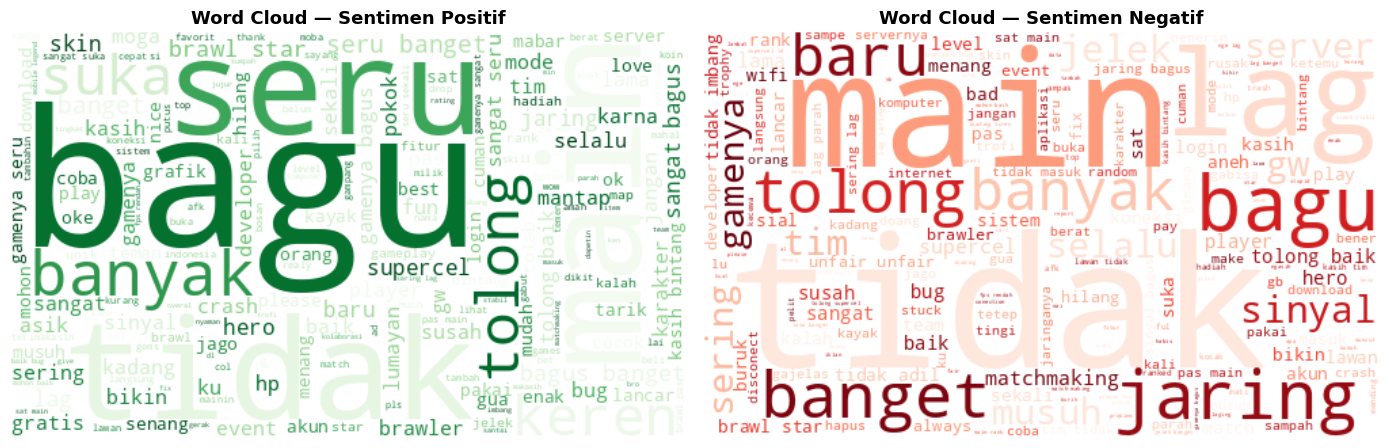

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sentimen_config = [(1, 'Positif', 'Greens'), (0, 'Negatif', 'Reds')]

for ax, (label, nama, cmap) in zip(axes, sentimen_config):
    teks = ' '.join(df[df['label'] == label]['ulasan_bersih'])
    wc   = WordCloud(width=500, height=300, background_color='white', colormap=cmap).generate(teks)
    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(f'Word Cloud — Sentimen {nama}', fontsize=13, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.savefig('output/wordcloud.png', dpi=150)
plt.show()

---
## 6. Persiapan Fitur & Label

In [ ]:
X_raw = df['ulasan_bersih']   # Raw text (belum divektorisasi)
y     = df['label']           # Label: 1=Positif, 0=Negatif

TFIDF_PARAMS = dict(
    max_features=3000,
    ngram_range=(1, 2),
    min_df=2
)

print(f'Total sampel : {len(X_raw)}')
print('Distribusi label:')
print(y.value_counts().rename({1: 'Positif (1)', 0: 'Negatif (0)'}).to_string())
print('\n✅ Raw text & label siap. TF-IDF akan di-fit hanya pada data training.')

Total sampel : 4584
Distribusi label:
label
Positif (1)    2492
Negatif (0)    2092

✅ Raw text & label siap. TF-IDF akan di-fit hanya pada data training.


---
## 7. Split Data (Train & Test)

In [ ]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f'Data train : {len(X_train_raw)} sampel')
print(f'Data test  : {len(X_test_raw)} sampel')
print('\nDistribusi train:')
print(y_train.value_counts().rename({1: 'Positif', 0: 'Negatif'}).to_string())
print('\nDistribusi test:')
print(y_test.value_counts().rename({1: 'Positif', 0: 'Negatif'}).to_string())

Data train : 3667 sampel
Data test  : 917 sampel

Distribusi train:
label
Positif    1993
Negatif    1674

Distribusi test:
label
Positif    499
Negatif    418


In [ ]:
# ============================================================
## 7b. Justifikasi Pemilihan max_features TF-IDF

from sklearn.model_selection import cross_val_score

max_features_list = [1000, 2000, 3000, 5000]
results_mf = []

for mf in max_features_list:
    pipe = Pipeline([
        ('tfidf', TfidfVectorizer(
            max_features=mf,
            ngram_range=(1, 2),
            min_df=2
        )),
        ('rf', RandomForestClassifier(
            n_estimators=100,
            random_state=42,
                  class_weight='balanced',
                  n_jobs=-1
        ))
    ])
    scores = cross_val_score(
        pipe, X_train_raw, y_train,
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
        scoring='f1_weighted',
        n_jobs=-1
    )
    results_mf.append({
        'max_features': mf,
        'F1 Mean'     : round(scores.mean(), 4),
        'F1 Std'      : round(scores.std(), 4),
    })

df_mf = pd.DataFrame(results_mf)
print('Perbandingan max_features TF-IDF:')
print(df_mf.to_string(index=False))

best_mf = df_mf.loc[df_mf['F1 Mean'].idxmax(), 'max_features']
print(f'\n✅ max_features terbaik: {best_mf} → digunakan di TFIDF_PARAMS')

# Update TFIDF_PARAMS dengan max_features terbaik hasil eksperimen
TFIDF_PARAMS['max_features'] = int(best_mf)
print(f'\n✅ TFIDF_PARAMS diperbarui → max_features = {int(best_mf)}')

Perbandingan max_features TF-IDF:
 max_features  F1 Mean  F1 Std
         1000   0.8271  0.0128
         2000   0.8296  0.0147
         3000   0.8285  0.0139
         5000   0.8271  0.0152

✅ max_features terbaik: 2000 → digunakan di TFIDF_PARAMS

✅ TFIDF_PARAMS diperbarui → max_features = 2000


---
## 8. Training Model Random Forest

In [ ]:
# Pipeline TF-IDF + Random Forest dengan class_weight untuk menangani class imbalance
pipeline_awal = Pipeline([
    ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
    ('rf',    RandomForestClassifier(
                  n_estimators=100,
                  max_depth=None,
                  random_state=42,
                  class_weight='balanced',
                  n_jobs=-1
              ))
])

pipeline_awal.fit(X_train_raw, y_train)

tfidf_fitted = pipeline_awal.named_steps['tfidf']
rf_fitted    = pipeline_awal.named_steps['rf']

print(f'Jumlah fitur TF-IDF : {len(tfidf_fitted.get_feature_names_out())}')
print('✅ Pipeline (TF-IDF + Random Forest) berhasil dilatih!')

Jumlah fitur TF-IDF : 2000
✅ Pipeline (TF-IDF + Random Forest) berhasil dilatih!


---
## 9. Evaluasi Model

In [ ]:
y_pred = pipeline_awal.predict(X_test_raw)

acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
rec  = recall_score(y_test, y_pred,    average='weighted', zero_division=0)
f1   = f1_score(y_test, y_pred,        average='weighted', zero_division=0)

print('=' * 45)
print(f'  Accuracy  : {acc:.4f} ({acc*100:.2f}%)')
print(f'  Precision : {prec:.4f}')
print(f'  Recall    : {rec:.4f}')
print(f'  F1-Score  : {f1:.4f}')
print('=' * 45)
print()
print('Classification Report (Model Awal):')
print(classification_report(y_test, y_pred,
      target_names=['Negatif', 'Positif'], zero_division=0))

  Accuracy  : 0.8582 (85.82%)
  Precision : 0.8597
  Recall    : 0.8582
  F1-Score  : 0.8585

Classification Report (Model Awal):
              precision    recall  f1-score   support

     Negatif       0.83      0.87      0.85       418
     Positif       0.89      0.85      0.87       499

    accuracy                           0.86       917
   macro avg       0.86      0.86      0.86       917
weighted avg       0.86      0.86      0.86       917



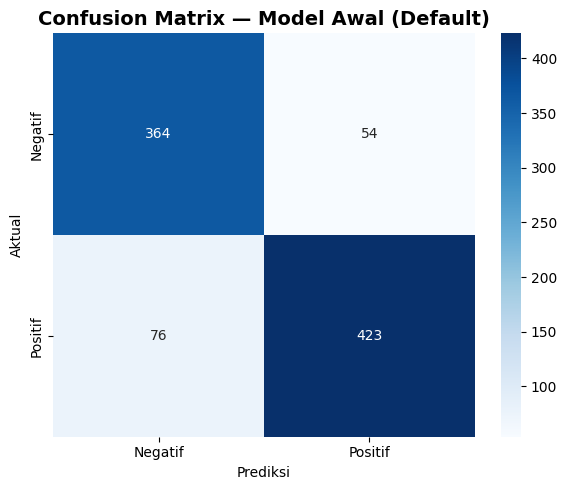

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negatif', 'Positif'],
            yticklabels=['Negatif', 'Positif'])
plt.title('Confusion Matrix — Model Awal (Default)', fontsize=14, fontweight='bold')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.tight_layout()
plt.savefig('output/confusion_matrix.png', dpi=150)
plt.show()

/tmp/ipykernel_801/3531931436.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_features, x='Importance', y='Fitur', palette='viridis')


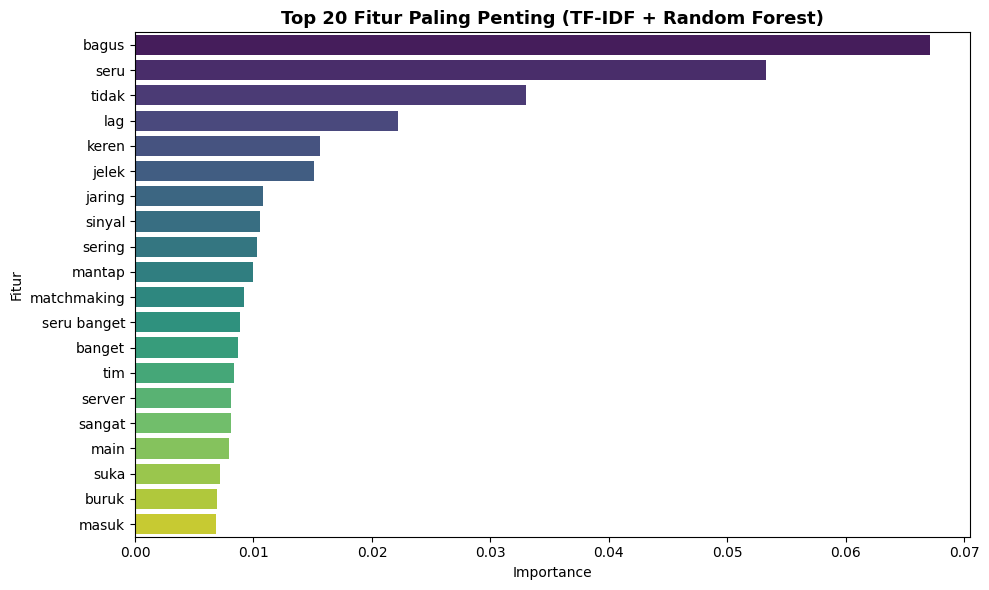

In [ ]:
feature_names = tfidf_fitted.get_feature_names_out()
importances   = rf_fitted.feature_importances_
top_n         = 20

top_idx      = np.argsort(importances)[::-1][:top_n]
top_features = pd.DataFrame({
    'Fitur'     : feature_names[top_idx],
    'Importance': importances[top_idx],
})

plt.figure(figsize=(10, 6))
sns.barplot(data=top_features, x='Importance', y='Fitur', palette='viridis')
plt.title(f'Top {top_n} Fitur Paling Penting (TF-IDF + Random Forest)',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('output/feature_importance.png', dpi=150)
plt.show()

---
## 10. K-Fold Cross Validation (Baseline)

In [ ]:
pipeline_cv = Pipeline([
    ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
    ('rf',    RandomForestClassifier(
                  n_estimators=100,
                  random_state=42,
                  class_weight='balanced',
                  n_jobs=-1
              ))
])

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

scoring_cv = {
    'accuracy' : 'accuracy',
    'precision': make_scorer(precision_score, average='weighted', zero_division=0),
    'recall'   : make_scorer(recall_score,    average='weighted', zero_division=0),
    'f1'       : make_scorer(f1_score,        average='weighted', zero_division=0),
}

cv_results = cross_validate(
    pipeline_cv, X_train_raw, y_train,
    cv=skf, scoring=scoring_cv, return_train_score=False, n_jobs=-1
)

print('=' * 52)
print('  K-Fold Cross Validation (k=10) — Baseline')
print('=' * 52)
for metric in ['accuracy', 'precision', 'recall', 'f1']:
    vals = cv_results[f'test_{metric}']
    print(f'  {metric.capitalize():<12}: {vals.mean():.4f} ± {vals.std():.4f}  '
          f'[min={vals.min():.4f}, max={vals.max():.4f}]')
print('=' * 52)

  K-Fold Cross Validation (k=10) — Baseline
  Accuracy    : 0.8236 ± 0.0235  [min=0.7711, max=0.8529]
  Precision   : 0.8265 ± 0.0229  [min=0.7750, max=0.8552]
  Recall      : 0.8236 ± 0.0235  [min=0.7711, max=0.8529]
  F1          : 0.8239 ± 0.0235  [min=0.7716, max=0.8531]


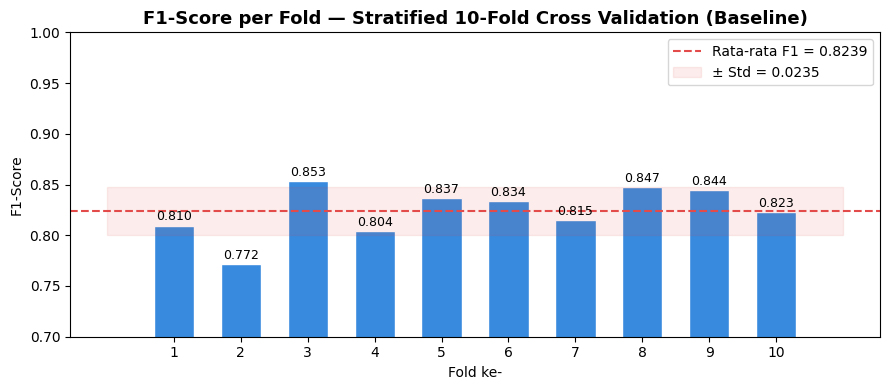

⚠️  Std cukup (<0.05) → model relatif stabil, namun ada sedikit variasi antar fold.


In [ ]:
f1_baseline = cv_results['test_f1']

plt.figure(figsize=(9, 4))
bars = plt.bar(range(1, 11), f1_baseline, color='#378ADD', edgecolor='white', width=0.6)
plt.axhline(f1_baseline.mean(), color='#E24B4A', linestyle='--', linewidth=1.5,
            label=f'Rata-rata F1 = {f1_baseline.mean():.4f}')
plt.fill_between(range(0, 12),
                 f1_baseline.mean() - f1_baseline.std(),
                 f1_baseline.mean() + f1_baseline.std(),
                 alpha=0.1, color='#E24B4A',
                 label=f'± Std = {f1_baseline.std():.4f}')
for bar, val in zip(bars, f1_baseline):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.002,
             f'{val:.3f}', ha='center', va='bottom', fontsize=9)
plt.title('F1-Score per Fold — Stratified 10-Fold Cross Validation (Baseline)',
          fontsize=13, fontweight='bold')
plt.xlabel('Fold ke-')
plt.ylabel('F1-Score')
plt.ylim(0.7, 1.0)
plt.xticks(range(1, 11))
plt.legend()
plt.tight_layout()
plt.savefig('output/kfold_f1_per_fold_baseline.png', dpi=150)
plt.show()

std_baseline = f1_baseline.std()
if std_baseline < 0.02:
    print('✅ Std sangat kecil (<0.02) → model stabil dan konsisten di semua fold.')
elif std_baseline < 0.05:
    print('⚠️  Std cukup (<0.05) → model relatif stabil, namun ada sedikit variasi antar fold.')
else:
    print('❌ Std besar (>0.05) → model tidak stabil, pertimbangkan tuning lebih lanjut.')

---
## 11. Simpan Model & Hasil

In [ ]:
rf_model = pipeline_awal
y_pred   = pipeline_awal.predict(X_test_raw)

joblib.dump(rf_model, 'output/pipeline_random_forest.pkl')
print('✅ Pipeline tersimpan: output/pipeline_random_forest.pkl')

df_test_result = df.loc[y_test.index].copy()
df_test_result['prediksi']      = y_pred
df_test_result['label_nama']    = df_test_result['label'].map({1: 'Positif', 0: 'Negatif'})
df_test_result['prediksi_nama'] = df_test_result['prediksi'].map({1: 'Positif', 0: 'Negatif'})
df_test_result['benar']         = (df_test_result['label'] == df_test_result['prediksi'])
df_test_result.to_excel('output/hasil_prediksi.xlsx', index=False)

print('✅ Hasil prediksi tersimpan: output/hasil_prediksi.xlsx')
print(f'\nRingkasan prediksi:')
print(f'  Benar : {df_test_result["benar"].sum()} dari {len(df_test_result)}')
print(f'  Salah : {(~df_test_result["benar"]).sum()} dari {len(df_test_result)}')

✅ Pipeline tersimpan: output/pipeline_random_forest.pkl
✅ Hasil prediksi tersimpan: output/hasil_prediksi.xlsx

Ringkasan prediksi:
  Benar : 787 dari 917
  Salah : 130 dari 917


---
## 12. Uji Prediksi Manual (Opsional)
> Gunakan untuk demo atau validasi tambahan.

In [ ]:
def prediksi_sentimen(teks_baru):
    """Prediksi sentimen teks baru menggunakan pipeline terbaik."""
    teks_bersih = preprocess(teks_baru)
    hasil = rf_model.predict([teks_bersih])[0]
    proba = rf_model.predict_proba([teks_bersih])[0]
    label = {1: 'Positif', 0: 'Negatif'}
    print(f'Input      : {teks_baru}')
    print(f'Teks bersih: {teks_bersih}')
    print(f'Sentimen   : {label[hasil]}')
    print(f'Confidence : Negatif={proba[0]:.2%} | Positif={proba[1]:.2%}')
    print()

prediksi_sentimen('Game ini sangat seru dan tidak bikin bosen!')
prediksi_sentimen('Banyak bug, sering crash. Sangat mengecewakan.')
prediksi_sentimen('Grafisnya bagus tapi loading lama banget.')

Input      : Game ini sangat seru dan tidak bikin bosen!
Teks bersih: sangat seru tidak bikin bosen
Sentimen   : Positif
Confidence : Negatif=5.00% | Positif=95.00%

Input      : Banyak bug, sering crash. Sangat mengecewakan.
Teks bersih: banyak bug sering crash sangat kecewa
Sentimen   : Negatif
Confidence : Negatif=84.44% | Positif=15.56%

Input      : Grafisnya bagus tapi loading lama banget.
Teks bersih: grafis bagus loading lama banget
Sentimen   : Positif
Confidence : Negatif=46.71% | Positif=53.29%



---
## 13. Analisis Stabilitas Split Ratio (dari Data Training)

In [ ]:
split_ratios  = [0.4, 0.3, 0.25, 0.1]
results_split = []

for test_size in split_ratios:
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_raw, y,            # Menggunakan seluruh data agar analisis lebih representatif
        test_size=test_size,
        stratify=y,
        random_state=42
    )

    pipeline_split = Pipeline([
        ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
        ('rf',    RandomForestClassifier(
                      n_estimators=100,
                      max_depth=None,
                      min_samples_split=2,
                      min_samples_leaf=1,
                      random_state=42,
                  class_weight='balanced',
                  n_jobs=-1
                  ))
    ])

    pipeline_split.fit(X_tr, y_tr)
    y_pred_split = pipeline_split.predict(X_te)

    results_split.append({
        'Test Size': test_size,
        'Accuracy' : accuracy_score(y_te, y_pred_split),
        'Precision': precision_score(y_te, y_pred_split, average='weighted', zero_division=0),
        'Recall'   : recall_score(y_te, y_pred_split,    average='weighted', zero_division=0),
        'F1-Score' : f1_score(y_te, y_pred_split,        average='weighted', zero_division=0),
    })

df_split = pd.DataFrame(results_split)
print('Perbandingan Performa Model pada Berbagai Rasio Split (dari Data Training):')
print(df_split.to_string(index=False))

Perbandingan Performa Model pada Berbagai Rasio Split (dari Data Training):
 Test Size  Accuracy  Precision   Recall  F1-Score
      0.40  0.841876   0.843130 0.841876  0.842102
      0.30  0.841570   0.842167 0.841570  0.841724
      0.25  0.849913   0.850672 0.849913  0.850082
      0.10  0.847495   0.849620 0.847495  0.847769


/tmp/ipykernel_801/3785311564.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Test Size', y='F1-Score', data=df_split, palette='viridis')


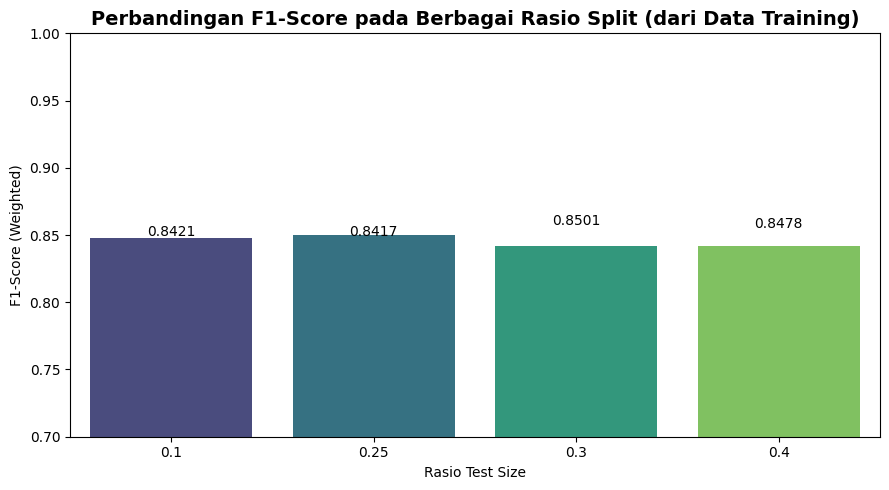

In [ ]:
plt.figure(figsize=(9, 5))
sns.barplot(x='Test Size', y='F1-Score', data=df_split, palette='viridis')
plt.title('Perbandingan F1-Score pada Berbagai Rasio Split (dari Data Training)',
          fontsize=14, fontweight='bold')
plt.xlabel('Rasio Test Size')
plt.ylabel('F1-Score (Weighted)')
plt.ylim(0.7, 1.0)
for idx, row in df_split.iterrows():
    plt.text(idx, row['F1-Score'] + 0.005,
             f"{row['F1-Score']:.4f}",
             color='black', ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.savefig('output/split_ratio_comparison_untuned.png', dpi=150)
plt.show()